# Customer Purchase Analytics with PySpark

Big data analysis of 1,000 customer purchase records using **Apache Spark (PySpark)**, Spark SQL and Spark MLlib.

**Pipeline:** load CSV → inspect schema → impute missing values → filter invalid rows → descriptive statistics →
outlier analysis (IQR) → correlation → Spark SQL queries → classification models (Decision Tree, Logistic Regression)
→ feature statistics and linear regression.

*Author: Pasang Rumba — MSc Software Engineering, University of West London (Big Data Analytics module).*

## 1. Start a Spark session and load the data

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col, when, corr
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

spark = SparkSession.builder.appName("CustomerPurchases").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

DATA_PATH = "../data/customer_purchases.csv"
dataframe = spark.read.csv(DATA_PATH, header=True, inferSchema=True)
dataframe.printSchema()
dataframe.show(5)
print("Rows:", dataframe.count())

root
 |-- CustomerID: integer (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Gender: string (nullable = true)
 |-- AnnualIncome: integer (nullable = true)
 |-- SpendingScore: integer (nullable = true)
 |-- PurchaseCategory: string (nullable = true)
 |-- TotalPurchases: integer (nullable = true)
 |-- PurchaseAmount: double (nullable = true)
 |-- Outcome: integer (nullable = true)

+----------+---+------+------------+-------------+----------------+--------------+--------------+-------+
|CustomerID|Age|Gender|AnnualIncome|SpendingScore|PurchaseCategory|TotalPurchases|PurchaseAmount|Outcome|
+----------+---+------+------------+-------------+----------------+--------------+--------------+-------+
|         1| 49|Female|           0|           94|          Sports|            20|           0.0|      1|
|         2| 34|Female|       89715|           80|         Fashion|             1|        236.01|      0|
|         3| 39|Female|       42910|           85|         Fashion|        

Rows: 1000


## 2. Data cleaning

Zero values in `SpendingScore` and `TotalPurchases` represent missing data, so they are replaced with the column median.

In [2]:
median_spending_score = dataframe.approxQuantile("SpendingScore", [0.5], 0)[0]
print(f"Median SpendingScore: {median_spending_score}")
df2 = dataframe.withColumn(
    "SpendingScore",
    when(col("SpendingScore") == 0, median_spending_score).otherwise(col("SpendingScore")),
)

median_total_purchases = dataframe.approxQuantile("TotalPurchases", [0.5], 0)[0]
print(f"Median TotalPurchases: {median_total_purchases}")
df2 = df2.withColumn(
    "TotalPurchases",
    when(col("TotalPurchases") == 0, median_total_purchases).otherwise(col("TotalPurchases")),
)
df2.show(5)

Median SpendingScore: 47.0
Median TotalPurchases: 10.0


+----------+---+------+------------+-------------+----------------+--------------+--------------+-------+
|CustomerID|Age|Gender|AnnualIncome|SpendingScore|PurchaseCategory|TotalPurchases|PurchaseAmount|Outcome|
+----------+---+------+------------+-------------+----------------+--------------+--------------+-------+
|         1| 49|Female|           0|         94.0|          Sports|          20.0|           0.0|      1|
|         2| 34|Female|       89715|         80.0|         Fashion|           1.0|        236.01|      0|
|         3| 39|Female|       42910|         85.0|         Fashion|           8.0|         50.24|      0|
|         4| 35|Female|       71190|         47.0|     Electronics|          10.0|         40.42|      0|
|         5|  0|  Male|       28451|         84.0|         Fashion|          16.0|        110.01|      1|
+----------+---+------+------------+-------------+----------------+--------------+--------------+-------+
only showing top 5 rows


Rows with zero `Age`, `AnnualIncome` or `PurchaseAmount` are invalid and are removed.

In [3]:
df3 = df2.filter((col("Age") != 0) & (col("AnnualIncome") != 0) & (col("PurchaseAmount") != 0))
print("Rows after filtering:", df3.count())
print("Rows removed:", df2.count() - df3.count())

Rows after filtering: 903
Rows removed: 97


## 3. Descriptive statistics for PurchaseAmount

Min: 5.91
Max: 499.97
Mean: 253.58
Variance: 21475.93
StdDev: 146.55
Median: 252.56


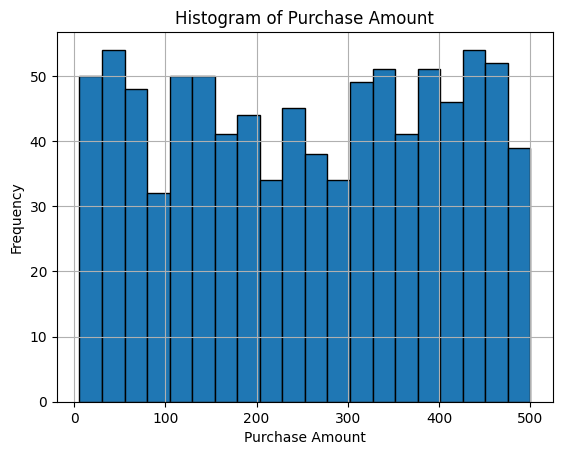

In [4]:
stats = df3.select(
    F.min("PurchaseAmount").alias("Min"),
    F.max("PurchaseAmount").alias("Max"),
    F.mean("PurchaseAmount").alias("Mean"),
    F.variance("PurchaseAmount").alias("Variance"),
    F.stddev("PurchaseAmount").alias("StdDev"),
).first()
median_value = df3.approxQuantile("PurchaseAmount", [0.5], 0.01)[0]

for name in ["Min", "Max", "Mean", "Variance", "StdDev"]:
    print(f"{name}: {stats[name]:.2f}")
print(f"Median: {median_value:.2f}")

pdf = df3.select("PurchaseAmount").toPandas()
plt.hist(pdf["PurchaseAmount"], bins=20, edgecolor="black")
plt.xlabel("Purchase Amount")
plt.ylabel("Frequency")
plt.title("Histogram of Purchase Amount")
plt.grid(True)
plt.show()

## 4. Outlier analysis for TotalPurchases (IQR method)

Q1=6.0, Q3=15.0, IQR=9.0, bounds=(-7.5, 28.5), outliers=0


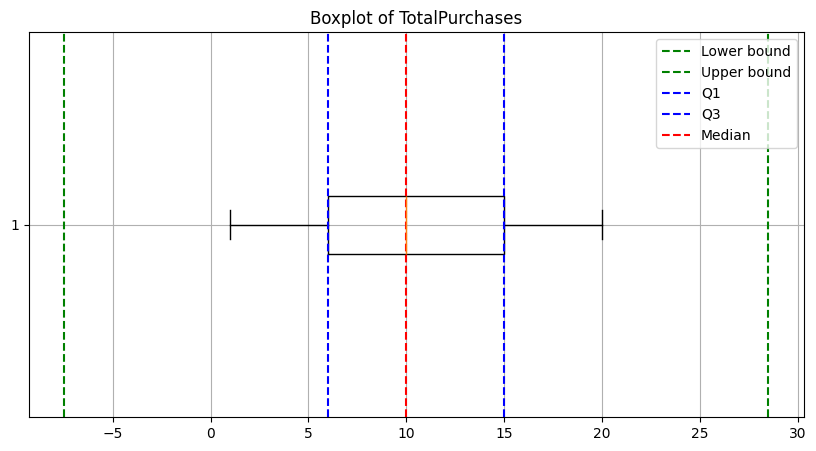

In [5]:
tp = df3.select("TotalPurchases").toPandas()["TotalPurchases"]
q1, q3 = tp.quantile(0.25), tp.quantile(0.75)
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = tp[(tp < lower_bound) | (tp > upper_bound)]
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, bounds=({lower_bound}, {upper_bound}), outliers={len(outliers)}")

plt.figure(figsize=(10, 5))
plt.boxplot(tp, vert=False)
plt.axvline(lower_bound, color="g", linestyle="--", label="Lower bound")
plt.axvline(upper_bound, color="g", linestyle="--", label="Upper bound")
plt.axvline(q1, color="b", linestyle="--", label="Q1")
plt.axvline(q3, color="b", linestyle="--", label="Q3")
plt.axvline(tp.median(), color="r", linestyle="--", label="Median")
plt.title("Boxplot of TotalPurchases")
plt.legend()
plt.grid(True)
plt.show()

## 5. Correlation between PurchaseAmount and SpendingScore

Pearson correlation: -0.0161


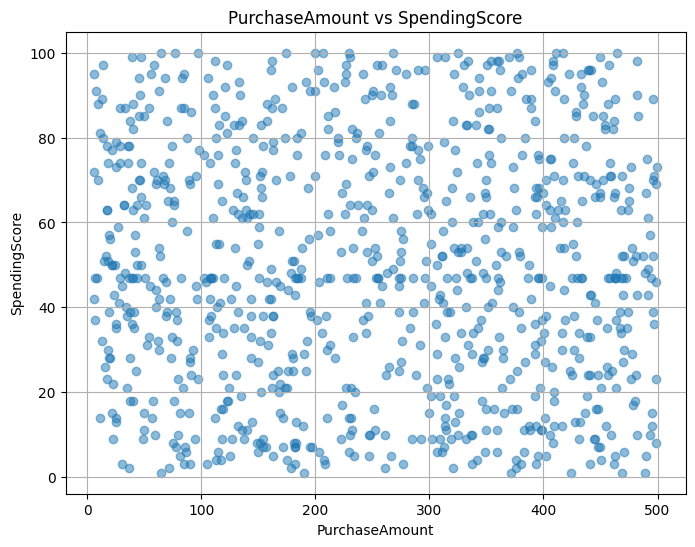

In [6]:
pearson = df3.select(corr("PurchaseAmount", "SpendingScore")).collect()[0][0]
print(f"Pearson correlation: {pearson:.4f}")

points = df3.select("PurchaseAmount", "SpendingScore").toPandas()
plt.figure(figsize=(8, 6))
plt.scatter(points["PurchaseAmount"], points["SpendingScore"], alpha=0.5)
plt.title("PurchaseAmount vs SpendingScore")
plt.xlabel("PurchaseAmount")
plt.ylabel("SpendingScore")
plt.grid(True)
plt.show()

## 6. Spark SQL query

In [7]:
df3.createOrReplaceTempView("customers")
spark.sql("""
    SELECT PurchaseCategory,
           COUNT(*)                      AS customers,
           ROUND(AVG(PurchaseAmount), 2) AS avg_purchase,
           ROUND(AVG(SpendingScore), 1)  AS avg_spending_score
    FROM customers
    WHERE Age < 50
    GROUP BY PurchaseCategory
    ORDER BY avg_purchase DESC
""").show()

+----------------+---------+------------+------------------+
|PurchaseCategory|customers|avg_purchase|avg_spending_score|
+----------------+---------+------------+------------------+
|          Sports|      108|      268.86|              46.7|
|  Home & Kitchen|       87|      259.67|              50.4|
|           Books|      116|      248.61|              49.7|
|         Fashion|       98|      242.08|              51.9|
|         Grocery|       99|      241.29|              49.0|
|     Electronics|       82|      231.94|              51.7|
+----------------+---------+------------+------------------+



## 7. Classification: predicting `Outcome` with a Decision Tree (Spark MLlib)

In [8]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StringIndexer
from pyspark.ml.classification import DecisionTreeClassifier, LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

categorical_cols = ["Gender", "PurchaseCategory"]
indexers = [StringIndexer(inputCol=c, outputCol=c + "_index") for c in categorical_cols]
feature_cols = [c for c in df3.columns if c not in ["Outcome", "CustomerID"] + categorical_cols]
feature_cols += [c + "_index" for c in categorical_cols]
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

train_data, test_data = df3.randomSplit([0.7, 0.3], seed=42)

dt = DecisionTreeClassifier(labelCol="Outcome", featuresCol="features", maxDepth=5)
dt_model = Pipeline(stages=indexers + [assembler, dt]).fit(train_data)
dt_pred = dt_model.transform(test_data)
roc = BinaryClassificationEvaluator(labelCol="Outcome", metricName="areaUnderROC")
print(f"Decision Tree AUC-ROC: {roc.evaluate(dt_pred):.3f}")
print(dt_model.stages[-1].toDebugString[:1500])

Decision Tree AUC-ROC: 0.982
DecisionTreeClassificationModel: uid=DecisionTreeClassifier_6ef2090877b8, depth=5, numNodes=21, numClasses=2, numFeatures=7
  If (feature 2 <= 57.5)
   If (feature 2 <= 46.5)
    Predict: 0.0
   Else (feature 2 > 46.5)
    If (feature 2 <= 47.5)
     If (feature 4 <= 445.44)
      If (feature 1 <= 116989.0)
       Predict: 0.0
      Else (feature 1 > 116989.0)
       Predict: 1.0
     Else (feature 4 > 445.44)
      If (feature 3 <= 10.5)
       Predict: 0.0
      Else (feature 3 > 10.5)
       Predict: 1.0
    Else (feature 2 > 47.5)
     Predict: 0.0
  Else (feature 2 > 57.5)
   If (feature 3 <= 5.5)
    Predict: 0.0
   Else (feature 3 > 5.5)
    If (feature 4 <= 91.68)
     Predict: 0.0
    Else (feature 4 > 91.68)
     If (feature 2 <= 62.5)
      If (feature 4 <= 153.055)
       Predict: 1.0
      Else (feature 4 > 153.055)
       Predict: 0.0
     Else (feature 2 > 62.5)
      Predict: 1.0



## 8. Classification: Logistic Regression

In [9]:
lr = LogisticRegression(labelCol="Outcome", featuresCol="features")
lr_model = Pipeline(stages=indexers + [assembler, lr]).fit(train_data)
lr_pred = lr_model.transform(test_data)
pr = BinaryClassificationEvaluator(labelCol="Outcome", metricName="areaUnderPR")
print(f"Logistic Regression AUC-ROC: {roc.evaluate(lr_pred):.3f}")
print(f"Logistic Regression AUC-PR:  {pr.evaluate(lr_pred):.3f}")

Logistic Regression AUC-ROC: 0.929
Logistic Regression AUC-PR:  0.823


## 9. Feature statistics and linear regression

In [10]:
from pyspark.ml.stat import Summarizer
from pyspark.ml.regression import LinearRegression

numeric = ["Age", "AnnualIncome", "SpendingScore", "TotalPurchases", "PurchaseAmount"]
vec = VectorAssembler(inputCols=numeric, outputCol="numeric_features").transform(df3)
s = vec.select(
    Summarizer.mean(F.col("numeric_features")).alias("mean"),
    Summarizer.variance(F.col("numeric_features")).alias("variance"),
).collect()[0]
print(pd.DataFrame({"mean": s["mean"].toArray(), "variance": s["variance"].toArray()}, index=numeric))

lin = LinearRegression(featuresCol="numeric_features", labelCol="Outcome", maxIter=10,
                       regParam=0.3, elasticNetParam=0.8).fit(vec)
print("Coefficients:", lin.coefficients)
print("Intercept:", lin.intercept)
print(f"RMSE: {lin.summary.rootMeanSquaredError:.4f}  R2: {lin.summary.r2:.4f}")

                        mean      variance
Age                42.890365  2.111576e+02
AnnualIncome    69546.210410  8.429005e+08
SpendingScore      49.708749  8.109095e+02
TotalPurchases     10.447398  3.196813e+01
PurchaseAmount    253.578151  2.147593e+04


Coefficients: [0.0,0.0,0.0004832820091171456,0.0,0.0]
Intercept: 0.22514609131423993
RMSE: 0.4245  R2: 0.0366


In [11]:
spark.stop()